In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [2]:
# Load dataset
data = pd.read_csv('ToyotaCorolla_-_MLR[1].csv')

In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [4]:
# Identify non-numeric columns
non_numeric_cols = data.select_dtypes(include=['object']).columns

In [5]:
# Label Encoding (for ordinal variables)
le = LabelEncoder()
for col in non_numeric_cols:
    if data[col].nunique() <= 10: # Adjust the threshold as needed
        data[col] = le.fit_transform(data[col])

In [6]:
# One-Hot Encoding (for nominal variables)
data = pd.get_dummies(data, columns=non_numeric_cols)

In [7]:
# Exploratory Data Analysis (EDA)
print(data.describe()) # Summary statistics
print(data.corr()) # Correlation matrix

              Price    Age_08_04             KM           HP    Automatic  \
count   1436.000000  1436.000000    1436.000000  1436.000000  1436.000000   
mean   10730.824513    55.947075   68533.259749   101.502089     0.055710   
std     3626.964585    18.599988   37506.448872    14.981080     0.229441   
min     4350.000000     1.000000       1.000000    69.000000     0.000000   
25%     8450.000000    44.000000   43000.000000    90.000000     0.000000   
50%     9900.000000    61.000000   63389.500000   110.000000     0.000000   
75%    11950.000000    70.000000   87020.750000   110.000000     0.000000   
max    32500.000000    80.000000  243000.000000   192.000000     1.000000   

                cc        Doors  Cylinders        Gears      Weight  
count   1436.00000  1436.000000     1436.0  1436.000000  1436.00000  
mean    1576.85585     4.033426        4.0     5.026462  1072.45961  
std      424.38677     0.952677        0.0     0.188510    52.64112  
min     1300.00000     2.0

C:\Users\HARSHITHA\OneDrive\Desktop\pyhton\New folder\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\HARSHITHA\OneDrive\Desktop\pyhton\New folder\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\HARSHITHA\OneDrive\Desktop\pyhton\New folder\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\HARSHITHA\OneDrive\Desktop\pyhton\New folder\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: us

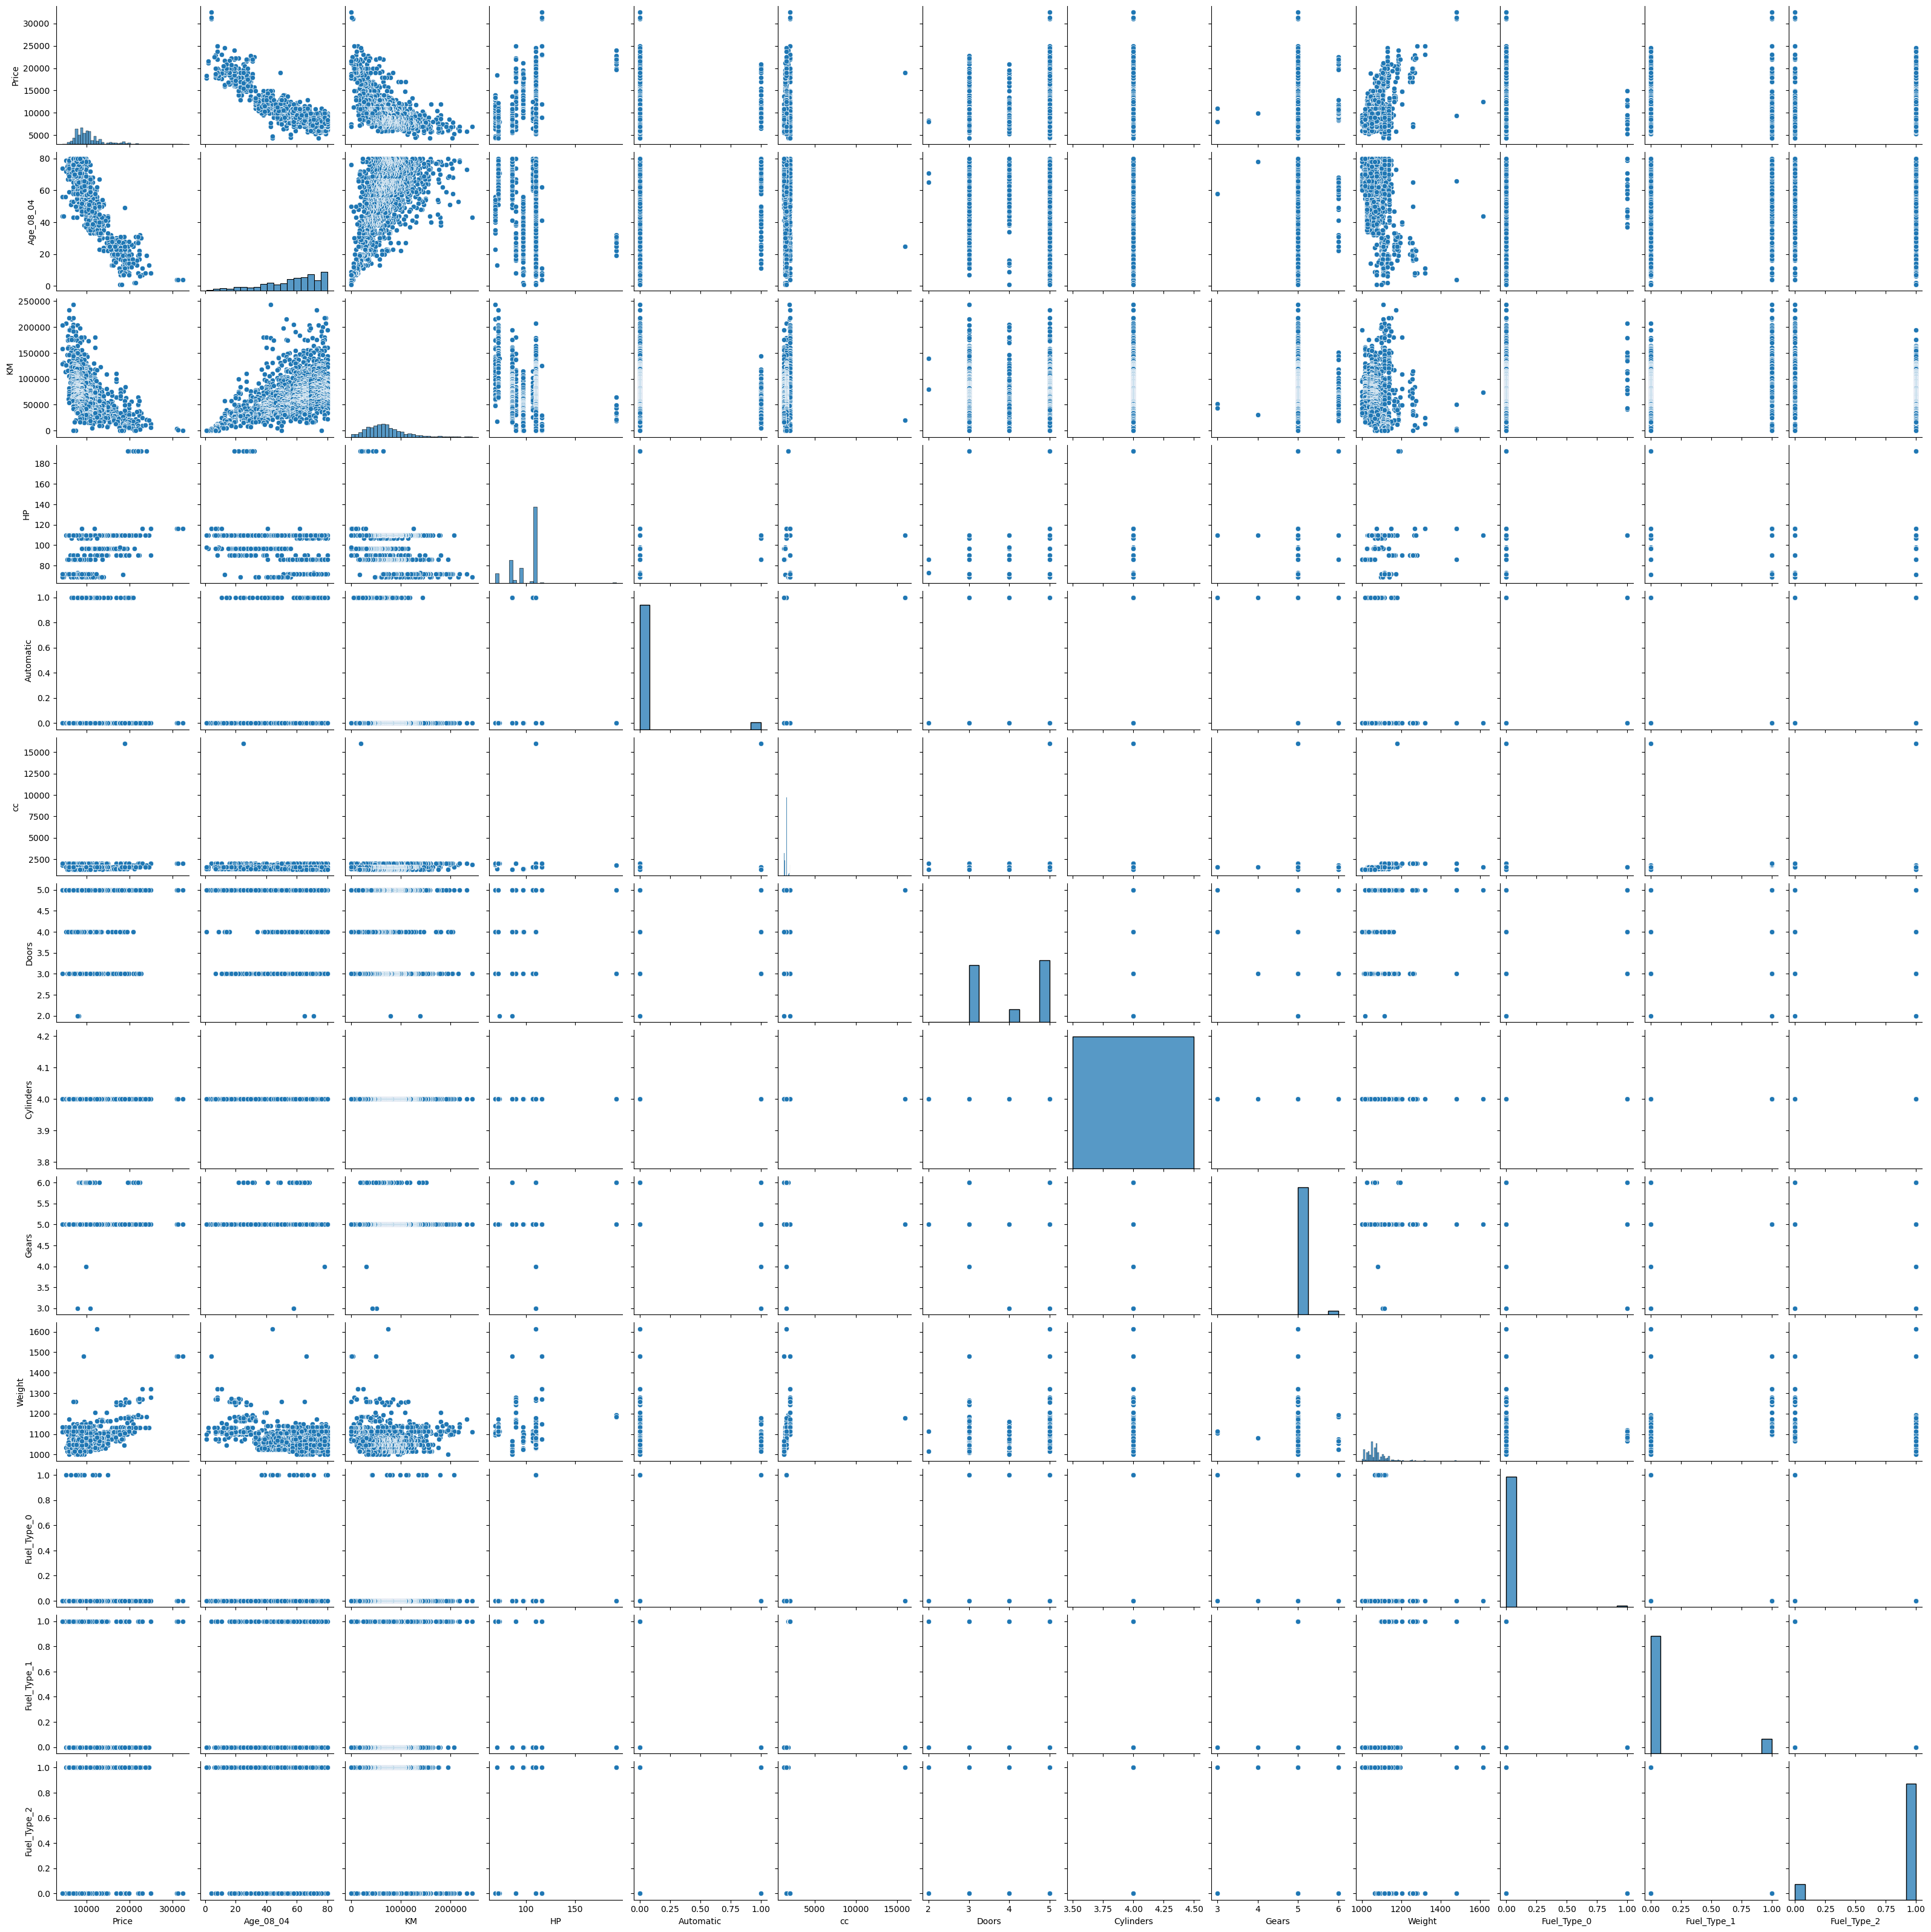

In [8]:
#Visualizations
sns.pairplot(data)
plt.show()

C:\Users\HARSHITHA\OneDrive\Desktop\pyhton\New folder\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


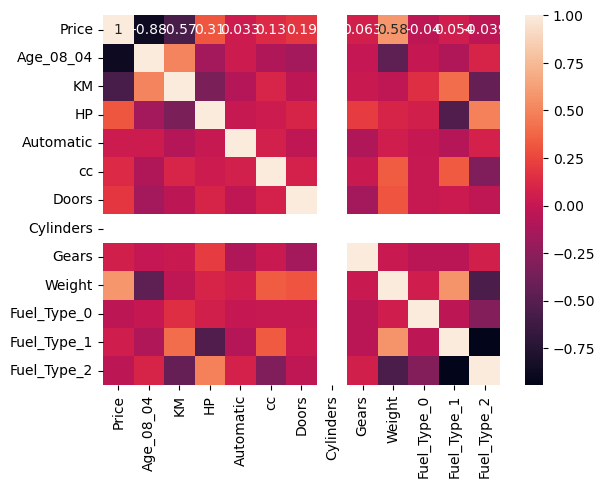

In [9]:
#correlation matrix
corr_matrix = data.corr()
sns.heatmap(corr_matrix,annot=True)
plt.show()

Text(0.5, 1.0, 'Target Variable Distribution')

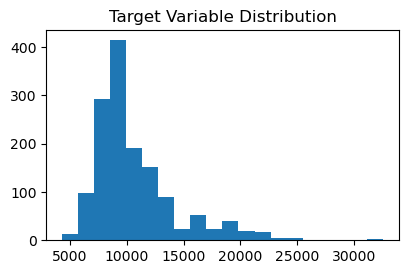

In [10]:
# Visualizations
plt.figure(figsize=(10, 6))
plt.subplot(2, 2, 1)
plt.hist(data['Price'], bins=20)
plt.title('Target Variable Distribution')

Text(0.5, 1.0, 'KM vs Price')

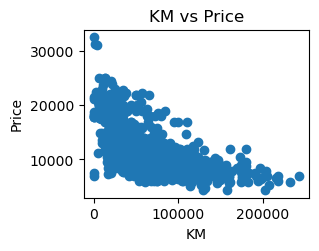

In [11]:
plt.subplot(2, 2, 2)
plt.scatter(data['KM'], data['Price'])
plt.xlabel('KM')
plt.ylabel('Price')
plt.title('KM vs Price')

Text(0.5, 1.0, 'HP vs Price')

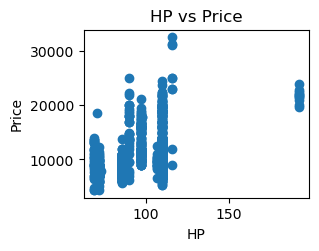

In [12]:
plt.subplot(2, 2, 3)
plt.scatter(data['HP'], data['Price'])
plt.xlabel('HP')
plt.ylabel('Price')
plt.title('HP vs Price')

In [13]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [14]:
# Preprocess data
scaler = StandardScaler()
data[['KM', 'HP']] = scaler.fit_transform(data[['KM', 'HP']])

In [15]:
# Split dataset into training and testing sets
X = data[['KM', 'HP']]
y = data['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
# Build multiple linear regression models
models = {
    'MLR': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1)
}

In [17]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

In [18]:
# Interpret coefficients
print(f"Model: {name}")
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_}")

Model: Lasso
Coefficients: [-1892.83175422   458.33050602]
Intercept: 10779.886211212057


In [19]:
# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"R2 Score: {r2:.2f}")
print()

MSE: 8522408.07
R2 Score: 0.36



In [20]:
#What is Normalization & Standardization and how is it helpful?
#Normalization (Min-Max Scaling): This rescales the feature values to a range of [0, 1] or [-1, 1]. It is useful when the data needs to be bounded and when the feature distributions vary significantly.
#Standardization (Z-score Scaling): This transforms the data to have a mean of 0 and a standard deviation of 1. It’s useful when the data follows a Gaussian distribution and helps in comparing features with different units or scales.
#2.What techniques can be used to address multicollinearity in multiple linear regression?
#Multicollinearity occurs when independent variables in a regression model are highly correlated, making it difficult to determine the effect of each variable. Techniques are removing Highly Correlated Predictors Identify and eliminate one of the correlated variables.
#Combining Variables Create composite variables through techniques like Principal Component Analysis (PCA) or feature engineering.